# Test-Set Evaluation: Tuned LSTM, Tuned 1D-CNN, and the Random Forest Baseline

Final evaluation on the reserved test months (Nov-Dec), following Sections 6.4-6.6 and 7.1 of the report.

**Inputs** (all produced by the earlier notebooks, expected in the working directory):

| File | Produced by |
|---|---|
| `baseline_engineered.parquet`, `engineered_feature_cols.json` | Baseline2 |
| `baseline_results.json` | Baseline2 (validation report of the RF, used as a reproduction check) |
| `final_hyperparameters.json` | Hyperparameters |

**Flow**
1. Retrain the two tuned sequence models with the selected hyperparameters (the Hyperparameters notebook did not save weights) and retrain the RF baseline exactly as in Baseline2. Only train and validation data are touched here.
2. Check that the retrained models reproduce the recorded validation scores.
3. Evaluate everything on the test months, once.
4. Classification reports, confusion matrices, regime-conditioned metrics, and a train / validation / test comparison.

In [1]:
# ---------------------------------------------------------------
# Imports and configuration
# ---------------------------------------------------------------
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score, f1_score)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

INPUT_PATH = Path("baseline_engineered.parquet")
FEATURE_LIST_PATH = Path("engineered_feature_cols.json")
HYPERPARAMS_PATH = Path("final_hyperparameters.json")
BASELINE_RESULTS_PATH = Path("baseline_results.json")
OUT_DIR = Path("test_evaluation")
OUT_DIR.mkdir(exist_ok=True)

# Same values as the Hyperparameters / Baseline2 notebooks
MAX_WINDOWS_PER_CLASS = 15_000   # training-window cap per class
MAX_EPOCHS = 30
PATIENCE = 5
RF_SAMPLE_SIZE = 500_000         # RF training rows (stratified)
MIN_REGIME_ROWS = 50             # skip regimes with fewer rows/windows than this

FORCE_RETRAIN = False            # True = ignore any weights saved in OUT_DIR

Using device: cuda


In [2]:
# ---------------------------------------------------------------
# Load data and build the same month-block split used everywhere else
# ---------------------------------------------------------------
with open(FEATURE_LIST_PATH) as f:
    engineered_feature_cols = json.load(f)

needed_cols = list(set(engineered_feature_cols + ["fault_type", "Datetime", "source_file", "n_chillers_on"]))
data = pd.read_parquet(INPUT_PATH, columns=needed_cols)

# Parquet row order == Baseline2's row order. Kept only so the RF baseline's stratified
# training sample can be redrawn exactly as Baseline2 drew it (before the re-sort below).
data["file_order"] = np.arange(len(data))

data["month"] = data["Datetime"].dt.month
data = data.sort_values(["source_file", "Datetime"]).reset_index(drop=True)

train_months, val_months, test_months = list(range(1, 9)), [9, 10], [11, 12]
data["split"] = np.select(
    [data["month"].isin(train_months), data["month"].isin(val_months), data["month"].isin(test_months)],
    ["train", "val", "test"], default="unused",
)
print(f"Loaded {data.shape[0]:,} rows;", data["split"].value_counts().to_dict())

Loaded 12,612,960 rows; {'train': 8396640, 'val': 2108160, 'test': 2108160}


In [3]:
# ---------------------------------------------------------------
# Label encoder, RobustScaler (fit on a training-row sample only), and ONE scaled
# feature matrix shared by every window dataset below. Windows are contiguous row
# ranges, so each window is just a slice of this matrix (no per-window copies).
# ---------------------------------------------------------------
label_encoder = LabelEncoder().fit(data["fault_type"])
CLASSES = list(label_encoder.classes_)
K = len(CLASSES)
n_features = len(engineered_feature_cols)

fit_sample_idx = data[data["split"] == "train"].sample(n=200_000, random_state=RANDOM_STATE).index
scaler = RobustScaler().fit(data.loc[fit_sample_idx, engineered_feature_cols].astype(np.float32))

def scale_in_chunks(df, cols, fitted_scaler, chunk=1_000_000):
    out = np.empty((len(df), len(cols)), dtype=np.float32)
    for s in range(0, len(df), chunk):
        out[s:s + chunk] = fitted_scaler.transform(df[cols].iloc[s:s + chunk].astype(np.float32))
    return out

feature_matrix = scale_in_chunks(data, engineered_feature_cols, scaler)
print(f"Classes ({K}): {CLASSES}")
print(f"Scaled feature matrix: {feature_matrix.shape}, {feature_matrix.nbytes / 1e9:.2f} GB")

Classes (9): ['bypass_leakage', 'bypass_stuck', 'chiller_bias', 'chiller_fouling', 'coolingtower_PI', 'coolingtower_bias', 'coolingtower_fouling', 'fault_free', 'secondary_chilled_water_pressure_bias']
Scaled feature matrix: (12612960, 50), 2.52 GB


In [4]:
# ---------------------------------------------------------------
# Window construction (identical to the Models / Hyperparameters notebooks) and a
# slice-based Dataset
# ---------------------------------------------------------------
def build_window_index(df, split_name, window_length, stride, max_per_class=None, random_state=RANDOM_STATE):
    windows = []
    split_df = df[df["split"] == split_name]
    for source_file, group in split_df.groupby("source_file", sort=False):
        group = group.sort_values("Datetime")
        n = len(group)
        if n < window_length:
            continue
        idx = group.index.to_numpy()
        label = group["fault_type"].iloc[0]
        for start in range(0, n - window_length + 1, stride):
            windows.append((idx[start:start + window_length], label))
    windows_df = pd.DataFrame(windows, columns=["row_idx", "fault_type"])
    if max_per_class is not None:
        parts = []
        for fault_type, group in windows_df.groupby("fault_type"):
            parts.append(group.sample(n=min(len(group), max_per_class), random_state=random_state))
        windows_df = pd.concat(parts, ignore_index=True)
    return windows_df.reset_index(drop=True)


class WindowSliceDataset(Dataset):
    # Window i = rows [starts[i], starts[i] + window_length) of the shared scaled matrix.
    def __init__(self, matrix, windows_df, label_encoder):
        row_idx = windows_df["row_idx"].to_numpy()
        n = len(row_idx)
        self.window_length = len(row_idx[0])
        self.starts = np.fromiter((a[0] for a in row_idx), dtype=np.int64, count=n)
        self.ends = np.fromiter((a[-1] for a in row_idx), dtype=np.int64, count=n)
        # Row positions are strictly increasing, so this implies the window is contiguous
        if not np.array_equal(self.ends - self.starts, np.full(n, self.window_length - 1)):
            raise ValueError("Window rows are not contiguous; slice-based dataset is not valid.")
        self.labels = label_encoder.transform(windows_df["fault_type"].to_numpy())
        self.X = matrix

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        s = self.starts[i]
        return torch.from_numpy(self.X[s:s + self.window_length]), torch.tensor(self.labels[i], dtype=torch.long)


def make_split(split_name, window_length, stride, max_per_class=None):
    # Returns (dataset, staging regime of each window's LAST row, per Section 6.6)
    windows_df = build_window_index(data, split_name, window_length, stride, max_per_class=max_per_class)
    ds = WindowSliceDataset(feature_matrix, windows_df, label_encoder)
    regimes = data["n_chillers_on"].to_numpy()[ds.ends]
    return ds, regimes

In [5]:
# ---------------------------------------------------------------
# Model classes (identical to the Models / Hyperparameters notebooks)
# ---------------------------------------------------------------
class LSTMClassifier(nn.Module):
    def __init__(self, n_features, hidden_size=64, num_layers=1, n_classes=9, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=hidden_size, num_layers=num_layers,
                            batch_first=True, dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, n_classes)

    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        return self.fc(self.dropout(h_n[-1]))


class CNN1DClassifier(nn.Module):
    def __init__(self, n_features, n_classes=9, channels=(64, 128), kernel_size=5, dropout=0.2):
        super().__init__()
        layers, in_ch = [], n_features
        for out_ch in channels:
            layers += [nn.Conv1d(in_ch, out_ch, kernel_size=kernel_size, padding=kernel_size // 2),
                       nn.ReLU(), nn.BatchNorm1d(out_ch)]
            in_ch = out_ch
        self.conv = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(channels[-1], n_classes)

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.pool(self.conv(x)).squeeze(-1)
        return self.fc(self.dropout(x))


def build_model(name, cfg):
    if name == "lstm":
        return LSTMClassifier(n_features, hidden_size=cfg["hidden_size"], num_layers=cfg["num_layers"], n_classes=K)
    return CNN1DClassifier(n_features, n_classes=K, channels=tuple(cfg["channels"]), kernel_size=cfg["kernel_size"])

In [6]:
# ---------------------------------------------------------------
# Training, prediction, and metric helpers
# ---------------------------------------------------------------
def train_model(model, train_ds, val_ds, class_weights_t, lr, batch_size,
                max_epochs=MAX_EPOCHS, patience=PATIENCE):
    # Same procedure as the tuning runs: weighted CE, Adam, early stopping on validation loss
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=0)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss(weight=class_weights_t)

    best_val_loss, epochs_no_improve, best_state = float("inf"), 0, None
    history = {"train_loss": [], "val_loss": []}
    for epoch in range(max_epochs):
        model.train()
        train_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * xb.size(0)
        train_loss /= len(train_ds)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                val_loss += criterion(model(xb), yb).item() * xb.size(0)
        val_loss /= len(val_ds)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        print(f"  epoch {epoch + 1:>2}/{max_epochs}  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}")

        if val_loss < best_val_loss:
            best_val_loss, epochs_no_improve = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"  early stopping at epoch {epoch + 1}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history


@torch.no_grad()
def predict_codes(model, ds, batch_size=512):
    model.eval()
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=0)
    return np.concatenate([model(xb.to(DEVICE)).argmax(dim=1).cpu().numpy() for xb, _ in loader])


def eval_split(model, ds, regimes):
    return {"y_true": ds.labels.copy(), "y_pred": predict_codes(model, ds),
            "regimes": regimes, "ends": ds.ends}


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=np.arange(K), average="macro", zero_division=0)


def per_class_f1(r):
    return pd.Series(f1_score(r["y_true"], r["y_pred"], labels=np.arange(K), average=None, zero_division=0),
                     index=CLASSES)


def regime_table(y_true, y_pred, regimes, min_rows=MIN_REGIME_ROWS):
    # macro_f1: classes present in y_true OR y_pred within the regime (matches the earlier notebooks)
    # macro_f1_supported: only classes that actually occur in y_true within the regime
    rows = []
    for regime in sorted(np.unique(regimes)):
        m = regimes == regime
        if m.sum() < min_rows:
            continue
        yt, yp = y_true[m], y_pred[m]
        rows.append({
            "n_chillers_on": regime, "n": int(m.sum()), "classes_present": len(np.unique(yt)),
            "accuracy": accuracy_score(yt, yp),
            "macro_f1": f1_score(yt, yp, labels=np.union1d(yt, yp), average="macro", zero_division=0),
            "macro_f1_supported": f1_score(yt, yp, labels=np.unique(yt), average="macro", zero_division=0),
        })
    return pd.DataFrame(rows)

In [7]:
# ---------------------------------------------------------------
# Tuned hyperparameters from the Hyperparameters notebook
# ---------------------------------------------------------------
with open(HYPERPARAMS_PATH) as f:
    final_configs = json.load(f)
print(json.dumps(final_configs, indent=2))

{
  "lstm": {
    "hidden_size": 64,
    "num_layers": 1,
    "lr": 0.003,
    "batch_size": 256,
    "window_length": 240,
    "stride": 15,
    "val_macro_f1": 0.5200283200975693
  },
  "cnn": {
    "channels": [
      64,
      128,
      256
    ],
    "kernel_size": 3,
    "lr": 0.001,
    "batch_size": 128,
    "window_length": 240,
    "stride": 15,
    "val_macro_f1": 0.6755945530110207
  }
}


## Step 1 - Retrain the tuned models (train + validation data only)

The test split is **not** touched in this section.


=== LSTM | {'hidden_size': 64, 'num_layers': 1, 'lr': 0.003, 'batch_size': 256, 'window_length': 240, 'stride': 15, 'val_macro_f1': 0.5200283200975693} ===
train windows: 135,000 | val windows: 140,184
  epoch  1/30  train_loss=1.5215  val_loss=1.3420
  epoch  2/30  train_loss=1.3621  val_loss=1.3346
  epoch  3/30  train_loss=1.3274  val_loss=1.3277
  epoch  4/30  train_loss=1.3576  val_loss=1.3404
  epoch  5/30  train_loss=1.3420  val_loss=1.3601
  epoch  6/30  train_loss=1.3778  val_loss=1.3677
  epoch  7/30  train_loss=1.2627  val_loss=1.3238
  epoch  8/30  train_loss=1.2565  val_loss=1.3022
  epoch  9/30  train_loss=1.2282  val_loss=1.2901
  epoch 10/30  train_loss=1.1836  val_loss=1.3758
  epoch 11/30  train_loss=1.1552  val_loss=1.4838
  epoch 12/30  train_loss=1.1153  val_loss=1.4800
  epoch 13/30  train_loss=1.2194  val_loss=1.2535
  epoch 14/30  train_loss=1.1354  val_loss=1.2655
  epoch 15/30  train_loss=1.1189  val_loss=1.1119
  epoch 16/30  train_loss=1.0678  val_loss=1.12

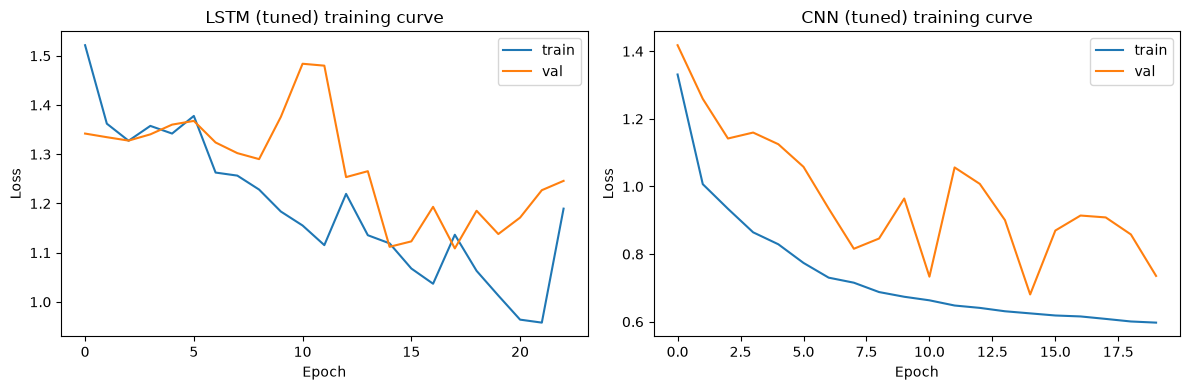

In [8]:
# ---------------------------------------------------------------
# Train the two tuned sequence models with their selected configuration, then score
# them on the training windows and validation windows. Weights are cached in OUT_DIR so
# re-running the notebook does not retrain unless the configuration changed.
# ---------------------------------------------------------------
res = {}          # res[model_key][split] = {"y_true", "y_pred", "regimes", "ends"}
trained = {}
histories = {}

for name in ["lstm", "cnn"]:
    cfg = final_configs[name]
    print(f"\n=== {name.upper()} | {cfg} ===")

    train_ds, train_regimes = make_split("train", cfg["window_length"], cfg["stride"], MAX_WINDOWS_PER_CLASS)
    val_ds, val_regimes = make_split("val", cfg["window_length"], cfg["stride"])
    print(f"train windows: {len(train_ds):,} | val windows: {len(val_ds):,}")

    counts = np.maximum(np.bincount(train_ds.labels, minlength=K), 1)
    class_weights_t = torch.tensor(len(train_ds) / (K * counts), dtype=torch.float32).to(DEVICE)

    model = build_model(name, cfg).to(DEVICE)
    weights_path = OUT_DIR / f"{name}_tuned.pt"
    ckpt = torch.load(weights_path, map_location=DEVICE) if (weights_path.exists() and not FORCE_RETRAIN) else None

    if ckpt is not None and ckpt["config"] == cfg:
        model.load_state_dict(ckpt["state_dict"])
        print(f"Loaded saved weights from {weights_path}")
    else:
        torch.manual_seed(RANDOM_STATE)
        model, histories[name] = train_model(model, train_ds, val_ds, class_weights_t,
                                             lr=cfg["lr"], batch_size=cfg["batch_size"])
        torch.save({"state_dict": model.state_dict(), "config": cfg}, weights_path)

    trained[name] = model
    res[name] = {"train": eval_split(model, train_ds, train_regimes),
                 "val": eval_split(model, val_ds, val_regimes)}
    print(f"train macro F1 = {macro_f1(res[name]['train']['y_true'], res[name]['train']['y_pred']):.4f} | "
          f"val macro F1 = {macro_f1(res[name]['val']['y_true'], res[name]['val']['y_pred']):.4f}")

if histories:
    fig, axes = plt.subplots(1, len(histories), figsize=(6 * len(histories), 4), squeeze=False)
    for ax, (name, h) in zip(axes[0], histories.items()):
        ax.plot(h["train_loss"], label="train"); ax.plot(h["val_loss"], label="val")
        ax.set_title(f"{name.upper()} (tuned) training curve"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.legend()
    plt.tight_layout(); plt.savefig(OUT_DIR / "training_curves.png", dpi=150); plt.show()

In [9]:
# ---------------------------------------------------------------
# Random Forest baseline - same procedure as the final Baseline2 variant
# (reduced features + regime-normalized columns; 500k stratified training rows,
# RobustScaler, 200 trees, balanced class weights)
# ---------------------------------------------------------------
# Redraw the stratified sample exactly as Baseline2 did: the training rows in ORIGINAL file order
train_rows = data.loc[data["split"] == "train", ["fault_type", "file_order"]].sort_values("file_order")
fault_train = train_rows["fault_type"]
sample_frac = min(1.0, RF_SAMPLE_SIZE / len(fault_train))
rf_sample_idx = pd.concat(
    [g.sample(frac=sample_frac, random_state=RANDOM_STATE) for _, g in fault_train.groupby(fault_train)]
).index
del train_rows, fault_train
print(f"RF training sample: {len(rf_sample_idx):,} rows")

scaler_rf = RobustScaler()
X_rf_train = scaler_rf.fit_transform(data.loc[rf_sample_idx, engineered_feature_cols].astype(np.float32))
y_rf_train = data.loc[rf_sample_idx, "fault_type"]

rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_rf_train, y_rf_train)

def rf_predict_rows(positions):
    X = scaler_rf.transform(data.iloc[positions][engineered_feature_cols].astype(np.float32))
    return label_encoder.transform(rf.predict(X))

# Row-level predictions for the whole validation split; kept in a position-indexed array so the
# RF can also be scored on exactly the rows that end each sequence-model window
rf_codes = np.full(len(data), -1, dtype=np.int16)
rf_regime_all = data["n_chillers_on"].to_numpy()
rf_true_all = label_encoder.transform(data["fault_type"])

def rf_eval_rows(split_name):
    pos = np.flatnonzero((data["split"] == split_name).to_numpy())
    rf_codes[pos] = rf_predict_rows(pos)
    return {"y_true": rf_true_all[pos], "y_pred": rf_codes[pos].astype(int),
            "regimes": rf_regime_all[pos], "ends": pos}

def add_rf_aligned(split_name):
    # RF prediction at the final row of every window the sequence models were scored on
    for name in ["lstm", "cnn"]:
        r = res[name][split_name]
        codes = rf_codes[r["ends"]].astype(int)
        assert (codes >= 0).all(), "RF predictions missing for some window-end rows"
        res.setdefault(f"rf@{name}", {})[split_name] = {**r, "y_pred": codes}

# Train: in-sample on the RF's own training sample (shown for completeness)
res["rf"] = {"train": {"y_true": label_encoder.transform(y_rf_train),
                       "y_pred": label_encoder.transform(rf.predict(X_rf_train)),
                       "regimes": rf_regime_all[data.index.get_indexer(rf_sample_idx)],
                       "ends": data.index.get_indexer(rf_sample_idx)}}
res["rf"]["val"] = rf_eval_rows("val")
add_rf_aligned("val")

print(f"RF train (in-sample) macro F1 = {macro_f1(res['rf']['train']['y_true'], res['rf']['train']['y_pred']):.4f} | "
      f"val macro F1 = {macro_f1(res['rf']['val']['y_true'], res['rf']['val']['y_pred']):.4f}")

RF training sample: 499,999 rows
RF train (in-sample) macro F1 = 0.9997 | val macro F1 = 0.6341


In [10]:
# ---------------------------------------------------------------
# Reproduction check: do the retrained models match what the earlier notebooks recorded?
# (Small differences are expected for the sequence models: GPU nondeterminism and a different
# RNG state than inside the tuning loop. Large gaps mean something differs in setup.)
# ---------------------------------------------------------------
with open(BASELINE_RESULTS_PATH) as f:
    recorded_rf = json.load(f)["reduced_regime_dev"]

rows = [
    {"model": "LSTM (tuned)", "metric": "val macro F1",
     "recorded": final_configs["lstm"]["val_macro_f1"],
     "retrained": macro_f1(res["lstm"]["val"]["y_true"], res["lstm"]["val"]["y_pred"])},
    {"model": "1D-CNN (tuned)", "metric": "val macro F1",
     "recorded": final_configs["cnn"]["val_macro_f1"],
     "retrained": macro_f1(res["cnn"]["val"]["y_true"], res["cnn"]["val"]["y_pred"])},
    {"model": "RF baseline", "metric": "val macro F1",
     "recorded": recorded_rf["macro avg"]["f1-score"],
     "retrained": macro_f1(res["rf"]["val"]["y_true"], res["rf"]["val"]["y_pred"])},
    {"model": "RF baseline", "metric": "val accuracy",
     "recorded": recorded_rf["accuracy"],
     "retrained": accuracy_score(res["rf"]["val"]["y_true"], res["rf"]["val"]["y_pred"])},
]
repro = pd.DataFrame(rows)
repro["difference"] = repro["retrained"] - repro["recorded"]
display(repro.round(4))

,model,metric,recorded,retrained,difference
0,LSTM (tuned),val macro F1,0.5200,0.5285,0.0085
1,1D-CNN (tuned),val macro F1,0.6756,0.6869,0.0113
2,RF baseline,val macro F1,0.6341,0.6341,0.0000
3,RF baseline,val accuracy,0.7334,0.7334,0.0000


## Step 2 - Evaluate on the reserved test months (run once)

Models and hyperparameters are fixed at this point. Do not retune or reselect anything after looking at these numbers.

In [11]:
# ---------------------------------------------------------------
# TEST evaluation: tuned LSTM, tuned 1D-CNN, RF baseline
# Each sequence model is scored on test windows built with ITS OWN tuned window length/stride.
# ---------------------------------------------------------------
for name in ["lstm", "cnn"]:
    cfg = final_configs[name]
    test_ds, test_regimes = make_split("test", cfg["window_length"], cfg["stride"])   # no cap on test
    res[name]["test"] = eval_split(trained[name], test_ds, test_regimes)
    print(f"{name.upper()}: {len(test_ds):,} test windows")

res["rf"]["test"] = rf_eval_rows("test")
print(f"RF: {len(res['rf']['test']['y_true']):,} test rows")
add_rf_aligned("test")

# If both sequence models use the same windows, a single window-aligned RF entry is enough
MODEL_LABELS = {"lstm": "LSTM (tuned)", "cnn": "1D-CNN (tuned)", "rf": "RF baseline (all rows)"}
same_windows = all(np.array_equal(res["rf@lstm"][s]["ends"], res["rf@cnn"][s]["ends"]) for s in ("val", "test"))
if same_windows:
    del res["rf@cnn"]
    MODEL_LABELS["rf@lstm"] = "RF baseline (window-end rows)"
else:
    MODEL_LABELS["rf@lstm"] = "RF baseline (@ LSTM windows)"
    MODEL_LABELS["rf@cnn"] = "RF baseline (@ CNN windows)"
ORDER = [k for k in ["lstm", "cnn", "rf", "rf@lstm", "rf@cnn"] if k in res]

headline = pd.DataFrame({
    MODEL_LABELS[k]: {"test n": len(res[k]["test"]["y_true"]),
                      "accuracy": accuracy_score(res[k]["test"]["y_true"], res[k]["test"]["y_pred"]),
                      "macro F1": macro_f1(res[k]["test"]["y_true"], res[k]["test"]["y_pred"])}
    for k in ORDER}).T
display(headline.round(4))

LSTM: 140,184 test windows
CNN: 140,184 test windows
RF: 2,108,160 test rows


,test n,accuracy,macro F1
LSTM (tuned),140184.0,0.5342,0.4237
1D-CNN (tuned),140184.0,0.5947,0.5759
RF baseline (all rows),2108160.0,0.7771,0.6781
RF baseline (window-end rows),140184.0,0.7765,0.6777


### Classification reports (test)

In [12]:
for k in ORDER:
    r = res[k]["test"]
    print(f"\n{'=' * 78}\n{MODEL_LABELS[k]} - TEST (n={len(r['y_true']):,})\n{'=' * 78}")
    print(classification_report(r["y_true"], r["y_pred"], labels=np.arange(K),
                                target_names=CLASSES, digits=3, zero_division=0))


LSTM (tuned) - TEST (n=140,184)
                                       precision    recall  f1-score   support

                       bypass_leakage      0.755     0.917     0.828     17523
                         bypass_stuck      0.754     0.379     0.504     11682
                         chiller_bias      0.955     0.984     0.970     23364
                      chiller_fouling      0.332     0.034     0.061     11682
                      coolingtower_PI      0.347     0.079     0.129      5841
                    coolingtower_bias      0.943     0.260     0.408     23364
                 coolingtower_fouling      0.248     0.952     0.394     17523
                           fault_free      0.038     0.031     0.034      5841
secondary_chilled_water_pressure_bias      0.957     0.325     0.485     23364

                             accuracy                          0.534    140184
                            macro avg      0.592     0.440     0.424    140184
                 

### Confusion matrices (test)

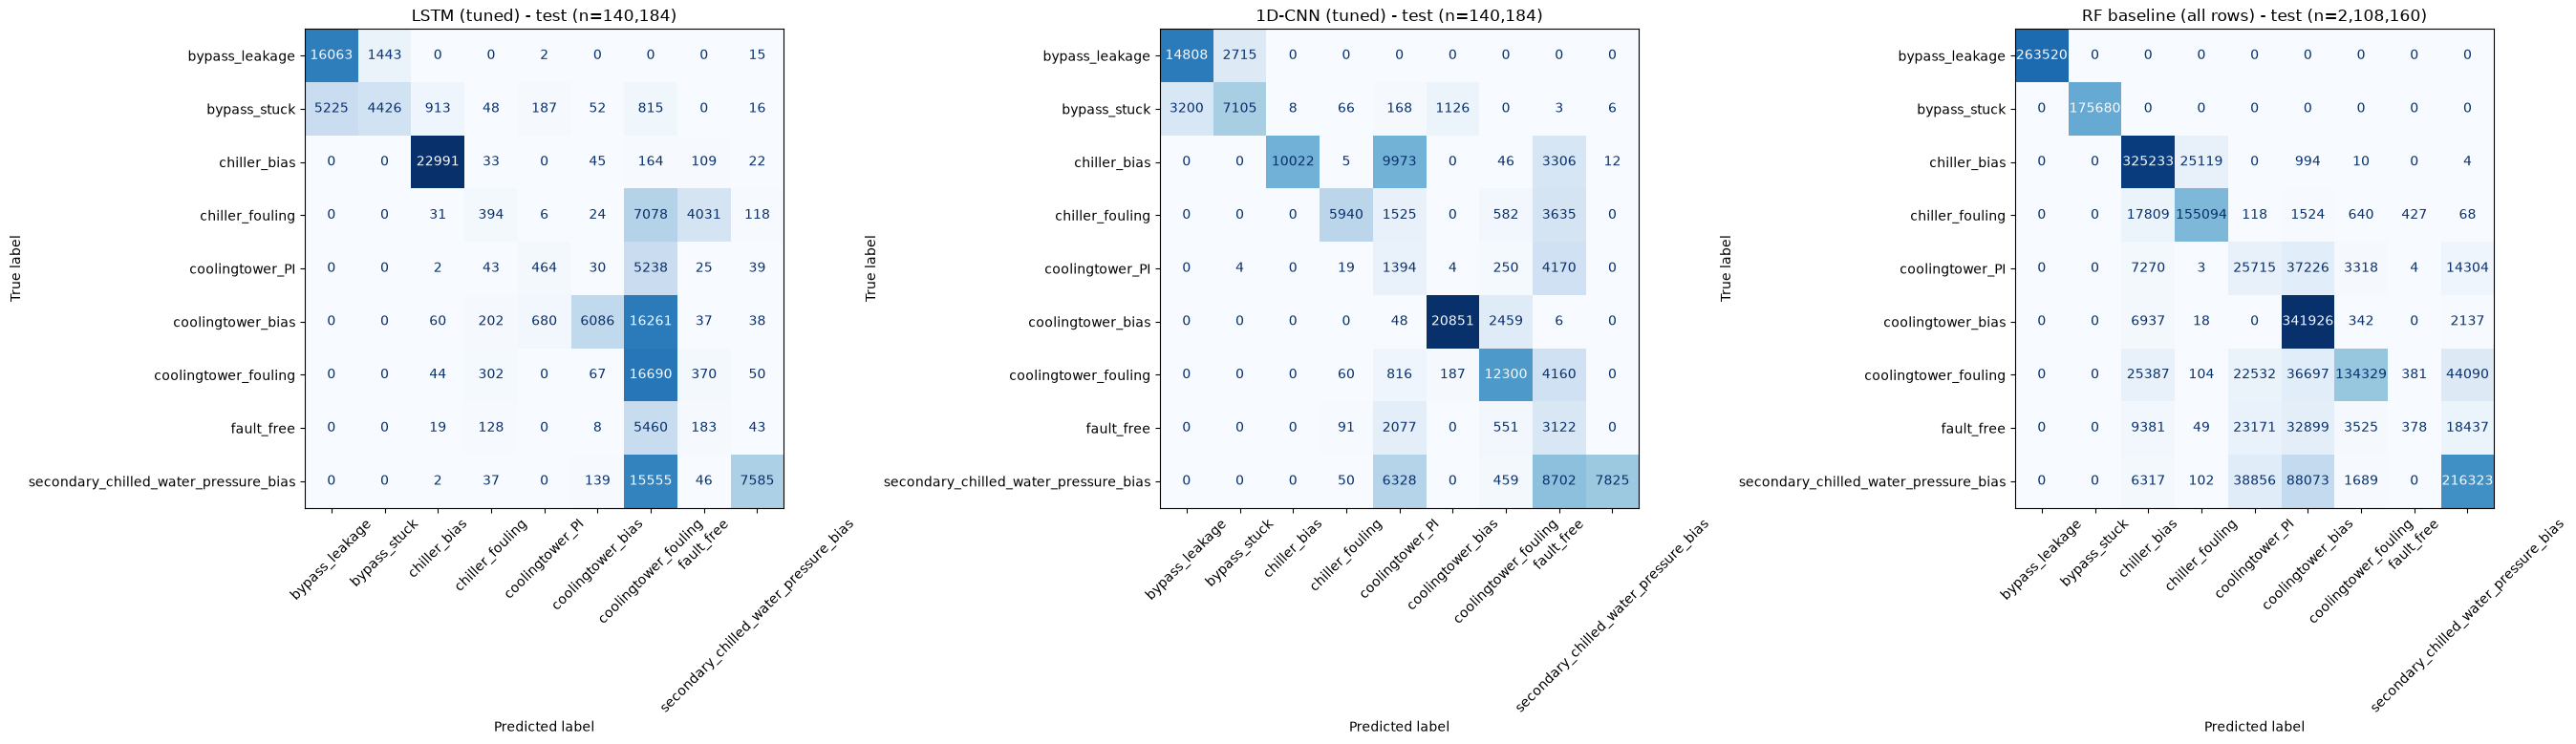

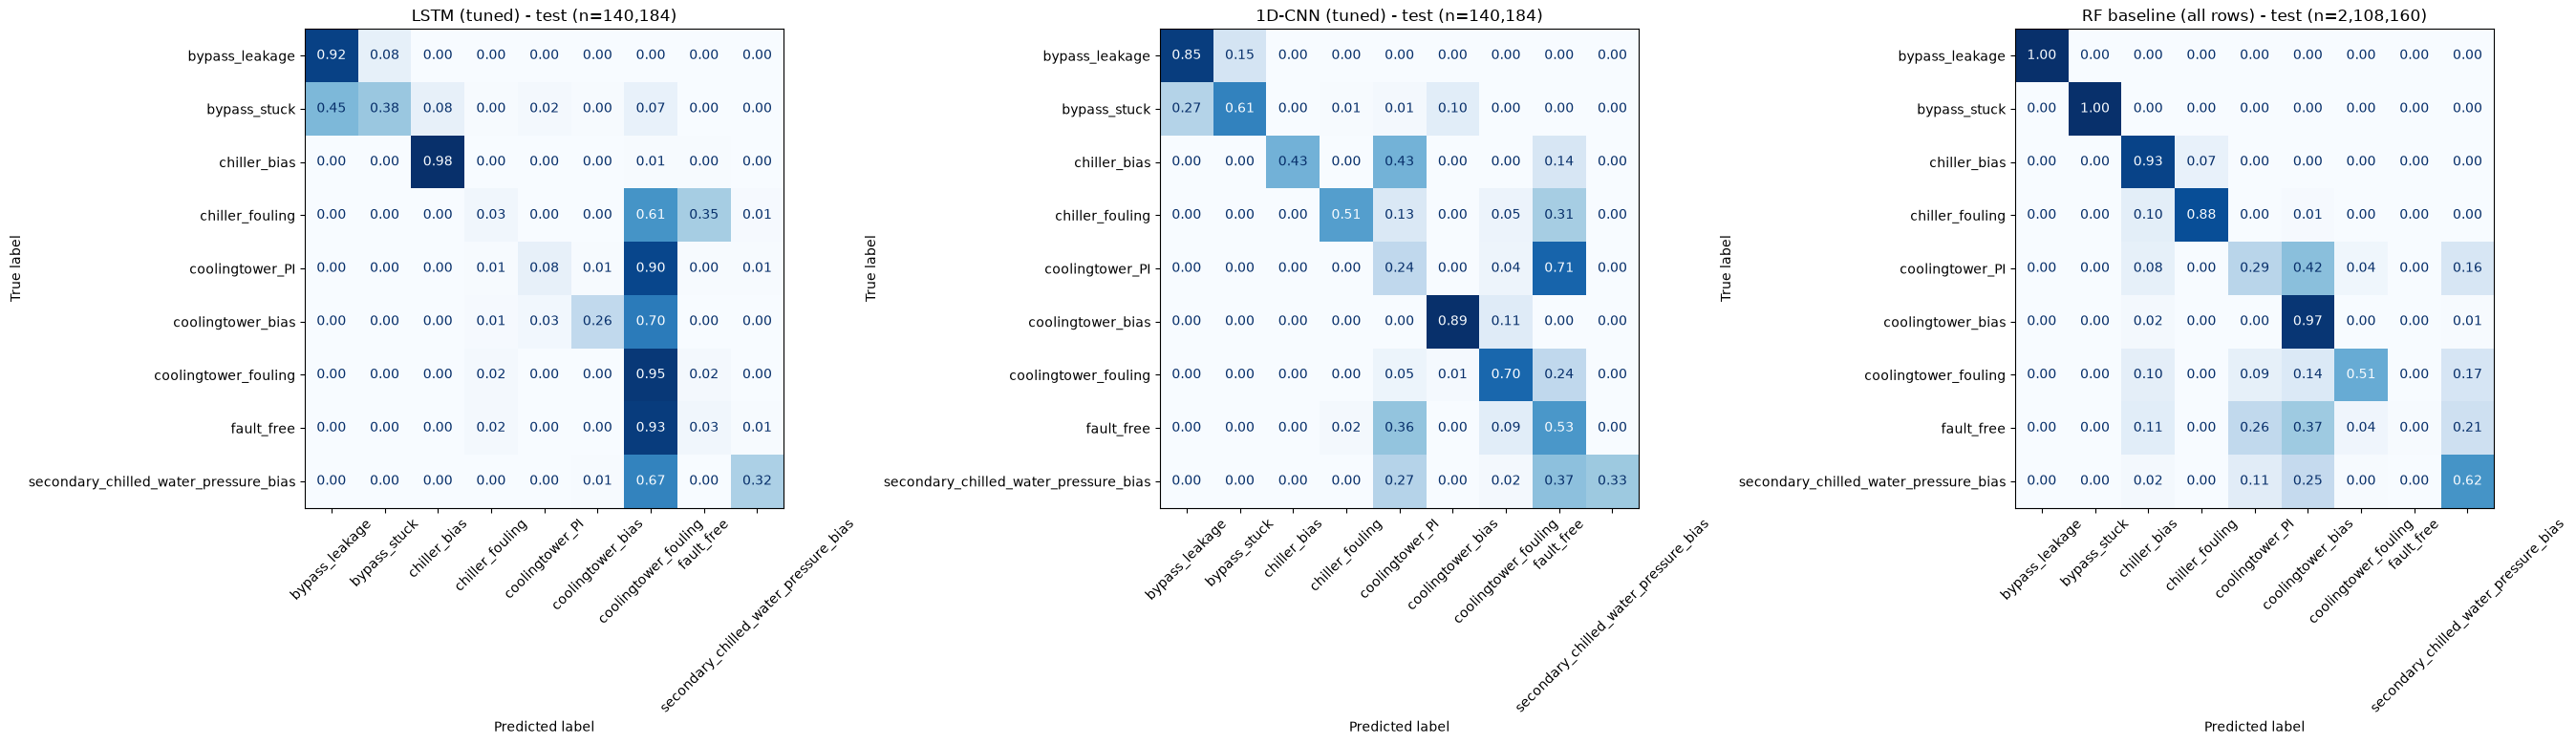

In [13]:
def plot_confusions(keys, split_name, normalize=None, fname=None):
    fig, axes = plt.subplots(1, len(keys), figsize=(9 * len(keys), 8))
    axes = np.atleast_1d(axes)
    for ax, k in zip(axes, keys):
        r = res[k][split_name]
        cm = confusion_matrix(r["y_true"], r["y_pred"], labels=np.arange(K), normalize=normalize)
        ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
            ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False,
            values_format=".2f" if normalize else "d")
        ax.set_title(f"{MODEL_LABELS[k]} - {split_name} (n={len(r['y_true']):,})")
    plt.tight_layout()
    if fname:
        plt.savefig(OUT_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()

cm_keys = ["lstm", "cnn", "rf"]
plot_confusions(cm_keys, "test", normalize=None, fname="confusion_test_counts.png")
plot_confusions(cm_keys, "test", normalize="true", fname="confusion_test_rownorm.png")   # each row sums to 1 (recall view)

### Regime-conditioned metrics (test and validation)

In [14]:
# Regime = number of chillers on at the window's last row (rows for the RF, per Section 6.6).
# `macro_f1_supported` only averages classes that occur in the regime; compare with `macro_f1`
# because some classes (e.g., bypass_stuck) have no multi-chiller rows at all.
frames = []
for k in ORDER:
    for split_name in ("val", "test"):
        r = res[k][split_name]
        t = regime_table(r["y_true"], r["y_pred"], r["regimes"])
        t.insert(0, "model", MODEL_LABELS[k]); t.insert(1, "split", split_name)
        frames.append(t)
regime_df = pd.concat(frames, ignore_index=True)

for split_name in ("test", "val"):
    print(f"\n--- {split_name.upper()} ---")
    sub = regime_df[regime_df["split"] == split_name]
    for metric in ["n", "accuracy", "macro_f1", "macro_f1_supported"]:
        pivot = sub.pivot(index="model", columns="n_chillers_on", values=metric).reindex([MODEL_LABELS[k] for k in ORDER])
        pivot.columns = [f"{c} chiller(s) on" for c in pivot.columns]
        print(f"\n{metric}")
        display(pivot.round(3) if metric != "n" else pivot)


--- TEST ---

n


,1.0 chiller(s) on,2.0 chiller(s) on
model,,
LSTM (tuned),140116,68
1D-CNN (tuned),140116,68
RF baseline (all rows),2107127,1033
RF baseline (window-end rows),140116,68



accuracy


,1.0 chiller(s) on,2.0 chiller(s) on
model,,
LSTM (tuned),0.534,0.309
1D-CNN (tuned),0.595,0.824
RF baseline (all rows),0.777,0.994
RF baseline (window-end rows),0.776,1.000



macro_f1


,1.0 chiller(s) on,2.0 chiller(s) on
model,,
LSTM (tuned),0.424,0.236
1D-CNN (tuned),0.576,0.452
RF baseline (all rows),0.678,0.499
RF baseline (window-end rows),0.678,1.000


... (6 outputs left out)


macro_f1


,1.0 chiller(s) on,2.0 chiller(s) on,3.0 chiller(s) on
model,,,
LSTM (tuned),0.542,0.292,0.050
1D-CNN (tuned),0.699,0.548,0.050
RF baseline (all rows),0.621,0.735,0.765
RF baseline (window-end rows),0.621,0.738,0.827



macro_f1_supported


,1.0 chiller(s) on,2.0 chiller(s) on,3.0 chiller(s) on
model,,,
LSTM (tuned),0.542,0.292,0.050
1D-CNN (tuned),0.699,0.548,0.050
RF baseline (all rows),0.621,0.735,0.765
RF baseline (window-end rows),0.621,0.738,0.827


### Training vs. validation vs. test

In [15]:
rows = []
for k in ORDER:
    for split_name, r in res[k].items():
        rows.append({"model": MODEL_LABELS[k], "split": split_name, "n": len(r["y_true"]),
                     "accuracy": accuracy_score(r["y_true"], r["y_pred"]),
                     "macro_f1": macro_f1(r["y_true"], r["y_pred"])})
summary = pd.DataFrame(rows)
order_labels = [MODEL_LABELS[k] for k in ORDER]

for metric in ["macro_f1", "accuracy"]:
    wide = summary.pivot(index="model", columns="split", values=metric).reindex(order_labels)
    wide = wide[[c for c in ["train", "val", "test"] if c in wide.columns]]
    wide["train - val"] = wide["train"] - wide["val"]
    wide["val - test"] = wide["val"] - wide["test"]
    print(f"\n{metric}")
    display(wide.round(4))
print("Notes: sequence-model 'train' = the capped 15k-per-class training windows; "
      "RF 'train' is in-sample on its own 500k-row sample; the window-aligned RF has no train entry.")

# Per-class F1 by split, one table per model
per_class_tables = {}
for k in ORDER:
    t = pd.DataFrame({s: per_class_f1(r) for s, r in res[k].items()})
    if "val" in t and "test" in t:
        t["test - val"] = t["test"] - t["val"]
    per_class_tables[k] = t
    print(f"\nPer-class F1 - {MODEL_LABELS[k]}")
    display(t.round(3))

# Test per-class F1 across models
cross = pd.DataFrame({MODEL_LABELS[k]: per_class_f1(res[k]["test"]) for k in ORDER})
cross.loc["Accuracy"] = [accuracy_score(res[k]["test"]["y_true"], res[k]["test"]["y_pred"]) for k in ORDER]
cross.loc["Macro F1"] = [macro_f1(res[k]["test"]["y_true"], res[k]["test"]["y_pred"]) for k in ORDER]
print("\nTest per-class F1, all models")
display(cross.round(3))


macro_f1


split,train,val,test,train - val,val - test
model,,,,,
LSTM (tuned),0.5395,0.5285,0.4237,0.0110,0.1048
1D-CNN (tuned),0.7333,0.6869,0.5759,0.0463,0.1110
RF baseline (all rows),0.9997,0.6341,0.6781,0.3656,-0.0440
RF baseline (window-end rows),NaN,0.6346,0.6777,NaN,-0.0431



accuracy


split,train,val,test,train - val,val - test
model,,,,,
LSTM (tuned),0.5376,0.5738,0.5342,-0.0362,0.0396
1D-CNN (tuned),0.7241,0.7261,0.5947,-0.0021,0.1314
RF baseline (all rows),0.9998,0.7334,0.7771,0.2664,-0.0437
RF baseline (window-end rows),NaN,0.7344,0.7765,NaN,-0.0421


Notes: sequence-model 'train' = the capped 15k-per-class training windows; RF 'train' is in-sample on its own 500k-row sample; the window-aligned RF has no train entry.

Per-class F1 - LSTM (tuned)


,train,val,test,test - val
bypass_leakage,0.790,0.797,0.828,0.031
bypass_stuck,0.853,0.739,0.504,-0.234
chiller_bias,0.787,0.804,0.970,0.165
chiller_fouling,0.377,0.230,0.061,-0.169
coolingtower_PI,0.523,0.466,0.129,-0.337
coolingtower_bias,0.553,0.550,0.408,-0.142
coolingtower_fouling,0.338,0.407,0.394,-0.014
fault_free,0.288,0.157,0.034,-0.123
secondary_chilled_water_pressure_bias,0.345,0.606,0.485,-0.121


... (4 outputs left out)


Per-class F1 - RF baseline (window-end rows)


,val,test,test - val
bypass_leakage,1.000,1.000,0.000
bypass_stuck,1.000,1.000,0.000
chiller_bias,0.795,0.867,0.072
chiller_fouling,0.699,0.870,0.171
coolingtower_PI,0.270,0.258,-0.011
coolingtower_bias,0.664,0.767,0.103
coolingtower_fouling,0.459,0.660,0.200
fault_free,0.056,0.009,-0.046
secondary_chilled_water_pressure_bias,0.768,0.668,-0.100



Test per-class F1, all models


,LSTM (tuned),1D-CNN (tuned),RF baseline (all rows),RF baseline (window-end rows)
bypass_leakage,0.828,0.834,1.000,1.000
bypass_stuck,0.504,0.661,1.000,1.000
chiller_bias,0.970,0.600,0.868,0.867
chiller_fouling,0.061,0.663,0.871,0.870
coolingtower_PI,0.129,0.099,0.259,0.258
coolingtower_bias,0.408,0.916,0.768,0.767
coolingtower_fouling,0.394,0.720,0.659,0.660
fault_free,0.034,0.190,0.008,0.009
secondary_chilled_water_pressure_bias,0.485,0.501,0.669,0.668
Accuracy,0.534,0.595,0.777,0.777


In [16]:
# ---------------------------------------------------------------
# Save results for the write-up (Table 7.1, Sections 7.2-7.3)
# ---------------------------------------------------------------
def to_builtin(o):
    return o.item() if hasattr(o, "item") else str(o)

reports = {}
for k in ORDER:
    reports[MODEL_LABELS[k]] = {
        s: classification_report(r["y_true"], r["y_pred"], labels=np.arange(K), target_names=CLASSES,
                                 output_dict=True, zero_division=0)
        for s, r in res[k].items()}
with open(OUT_DIR / "evaluation_reports.json", "w") as f:
    json.dump(reports, f, indent=2, default=to_builtin)

summary.to_csv(OUT_DIR / "train_val_test_summary.csv", index=False)
regime_df.to_csv(OUT_DIR / "regime_conditioned_metrics.csv", index=False)
cross.to_csv(OUT_DIR / "test_per_class_f1.csv")
repro.to_csv(OUT_DIR / "reproduction_check.csv", index=False)

arrays = {}
for k in ORDER:
    for s, r in res[k].items():
        for field in ("y_true", "y_pred", "regimes"):
            arrays[f"{k.replace('@', '_at_')}_{s}_{field}"] = np.asarray(r[field])
np.savez_compressed(OUT_DIR / "predictions.npz", **arrays, classes=np.array(CLASSES))

print("Saved to", OUT_DIR.resolve())
print(sorted(p.name for p in OUT_DIR.iterdir()))

Saved to C:\Users\tjoldham\Documents\Classes\MADS\Programming\DSCI8413\test_evaluation
['cnn_tuned.pt', 'confusion_test_counts.png', 'confusion_test_rownorm.png', 'evaluation_reports.json', 'lstm_tuned.pt', 'predictions.npz', 'regime_conditioned_metrics.csv', 'reproduction_check.csv', 'test_per_class_f1.csv', 'train_val_test_summary.csv', 'training_curves.png']
